# Iris Classification with Scikit-learn

## Purpose

In this assignment, I will practice solving classification problems using
the Iris dataset and scikit-learn.

The main steps are:

1. Select features and target classes
2. Analyze and visualize the data
3. Split the data into training and validation data
4. Standardize the features
5. Train classification models
6. Evaluate the models
7. Visualize decision regions
8. Compare different classification methods
9. Compare results with and without standardization
10. Perform multiclass classification using all three iris species

In [1]:
# Import NumPy for numerical operations
import numpy as np

# Import pandas for working with DataFrames
import pandas as pd

# Import matplotlib for visualization
import matplotlib.pyplot as plt

# Import seaborn for statistical plots
import seaborn as sns

# Load the Iris dataset from scikit-learn
from sklearn.datasets import load_iris

# Used to split data into training and validation sets
from sklearn.model_selection import train_test_split

# Used to standardize feature values
from sklearn.preprocessing import StandardScaler

# Classification models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

In [2]:
# Load the Iris dataset
iris = load_iris()

# Create a DataFrame containing the four features
iris_df = pd.DataFrame(
    iris.data,
    columns=[
        "sepal_length",
        "sepal_width",
        "petal_length",
        "petal_width"
    ]
)

# Add the target number
iris_df["target"] = iris.target

# Add the species name
iris_df["species"] = iris.target_names[iris.target]

# Display the first five rows
iris_df.head()

,sepal_length,sepal_width,petal_length,petal_width,target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:
# Select only versicolor and virginica
binary_df = iris_df[
    iris_df["species"].isin(["versicolor", "virginica"])
].copy()

# Select the two required features
X = binary_df[["sepal_length", "petal_length"]]

# Select the target
y = binary_df["target"]

# Display the first five rows
X.head()

,sepal_length,petal_length
50,7.0,4.7
51,6.4,4.5
52,6.9,4.9
53,5.5,4.0
54,6.5,4.6


In [4]:
# Count the number of samples in each class
print(y.value_counts())

# Display the species names and their counts
print(binary_df["species"].value_counts())

target
1    50
2    50
Name: count, dtype: int64
species
versicolor    50
virginica     50
Name: count, dtype: int64


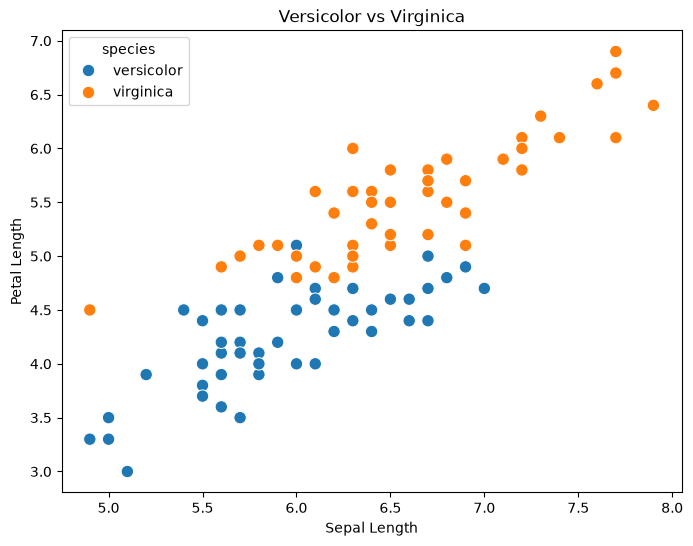

In [5]:
#PROBLEM 2
# Create a scatter plot of sepal length and petal length
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=binary_df,
    x="sepal_length",
    y="petal_length",
    hue="species",
    s=80
)

plt.title("Versicolor vs Virginica")
plt.xlabel("Sepal Length")
plt.ylabel("Petal Length")

plt.show()

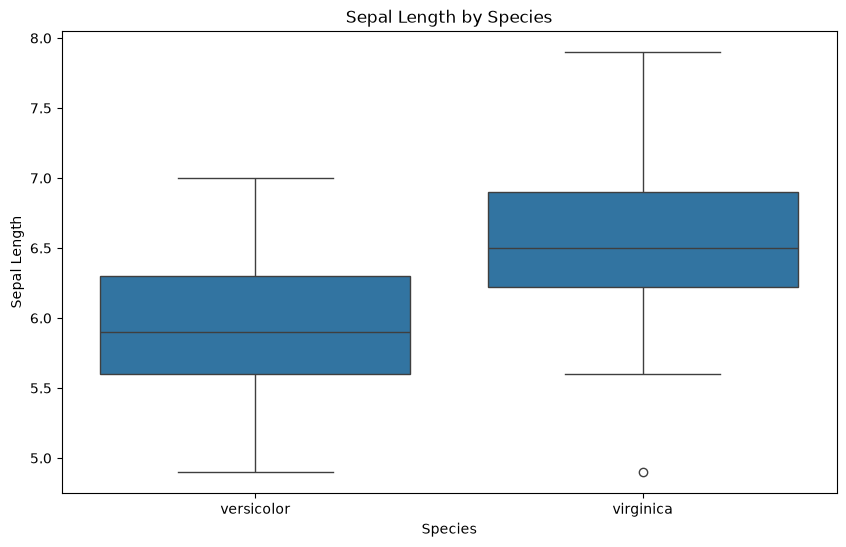

In [6]:
# Create boxplots for the two selected features
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=binary_df,
    x="species",
    y="sepal_length"
)

plt.title("Sepal Length by Species")
plt.xlabel("Species")
plt.ylabel("Sepal Length")

plt.show()

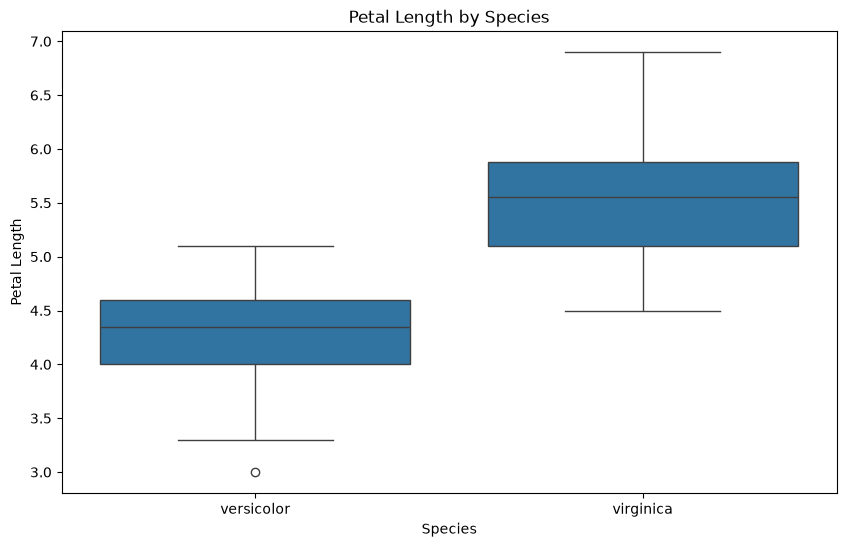

In [7]:
# Create a boxplot for petal length
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=binary_df,
    x="species",
    y="petal_length"
)

plt.title("Petal Length by Species")
plt.xlabel("Species")
plt.ylabel("Petal Length")

plt.show()

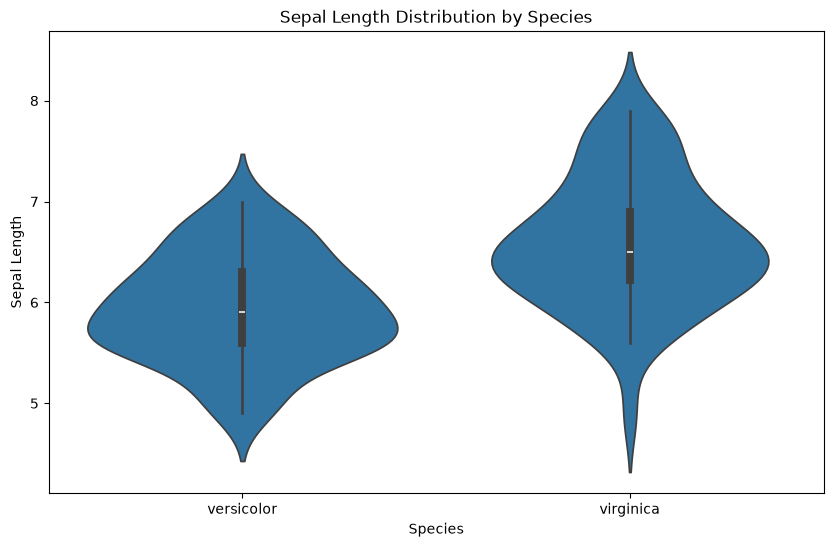

In [8]:
# Create a violin plot for sepal length
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=binary_df,
    x="species",
    y="sepal_length"
)

plt.title("Sepal Length Distribution by Species")
plt.xlabel("Species")
plt.ylabel("Sepal Length")

plt.show()

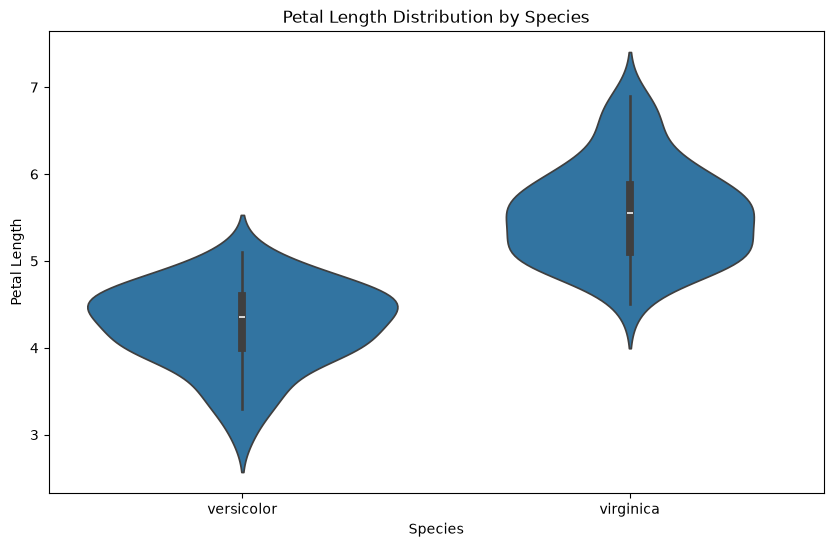

In [9]:
# Create a violin plot for petal length
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=binary_df,
    x="species",
    y="petal_length"
)

plt.title("Petal Length Distribution by Species")
plt.xlabel("Species")
plt.ylabel("Petal Length")

plt.show()

### Analysis

The scatter plot shows that versicolor and virginica have overlapping
regions when sepal length and petal length are used.

Petal length provides useful information for distinguishing the two species,
but the two classes are not perfectly separated.

The boxplots and violin plots show the distributions of the two features
for each species. They also show that there is some overlap between the
classes.

Therefore, classification is possible, but some samples may be difficult
for a model to classify correctly.

In [10]:
#PROBLEM 3
# Split the data into training and validation sets
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Display the shapes of the datasets
print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)

X_train: (75, 2)
X_valid: (25, 2)
y_train: (75,)
y_valid: (25,)


In [11]:
#PROBLEM 4
# Create the StandardScaler
scaler = StandardScaler()

# Learn the mean and standard deviation ONLY from training data
scaler.fit(X_train)

# Standardize the training data
X_train_scaled = scaler.transform(X_train)

# Use the same scaler to standardize validation data
X_valid_scaled = scaler.transform(X_valid)

# Display the first five standardized training samples
print(X_train_scaled[:5])

[[ 0.08837827  0.42173708]
 [-1.14480684 -0.0575096 ]
 [ 0.55082268 -0.65656795]
 [ 0.08837827  0.42173708]
 [-0.68236242  0.18211374]]


In [12]:
#PROBLEM 5# Create KNN models with different numbers of neighbors
knn_1 = KNeighborsClassifier(n_neighbors=1)
knn_3 = KNeighborsClassifier(n_neighbors=3)
knn_5 = KNeighborsClassifier(n_neighbors=5)

# Train each model using the standardized training data
knn_1.fit(X_train_scaled, y_train)
knn_3.fit(X_train_scaled, y_train)
knn_5.fit(X_train_scaled, y_train)

# Predict the validation data
y_pred_1 = knn_1.predict(X_valid_scaled)
y_pred_3 = knn_3.predict(X_valid_scaled)
y_pred_5 = knn_5.predict(X_valid_scaled)

# Display predictions
print("1-NN predictions:")
print(y_pred_1)

print("\n3-NN predictions:")
print(y_pred_3)

print("\n5-NN predictions:")
print(y_pred_5)


1-NN predictions:
[2 2 1 1 2 2 1 2 1 2 1 2 1 1 2 1 1 2 1 2 1 1 2 1 2]

3-NN predictions:
[2 2 1 1 2 2 2 2 2 2 1 2 1 1 2 1 1 2 1 2 1 2 2 1 2]

5-NN predictions:
[2 2 1 1 2 2 1 2 2 2 1 2 1 1 2 1 1 2 1 2 1 2 2 1 2]


In [13]:
#PROBLEM 6
def evaluate_model(y_true, y_pred, model_name):
    """
    Calculate and display classification metrics.
    
    Positive class:
    2 = virginica
    """
    
    accuracy = accuracy_score(y_true, y_pred)
    
    precision = precision_score(
        y_true,
        y_pred,
        pos_label=2
    )
    
    recall = recall_score(
        y_true,
        y_pred,
        pos_label=2
    )
    
    f1 = f1_score(
        y_true,
        y_pred,
        pos_label=2
    )
    
    print(f"--- {model_name} ---")
    print(f"Accuracy : {accuracy:.3f}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall   : {recall:.3f}")
    print(f"F1 score : {f1:.3f}")

In [14]:
def evaluate_model(y_true, y_pred, model_name):
    """
    Calculate and display classification metrics.
    
    Positive class:
    2 = virginica
    """
    
    accuracy = accuracy_score(y_true, y_pred)
    
    precision = precision_score(
        y_true,
        y_pred,
        pos_label=2
    )
    
    recall = recall_score(
        y_true,
        y_pred,
        pos_label=2
    )
    
    f1 = f1_score(
        y_true,
        y_pred,
        pos_label=2
    )
    
    print(f"--- {model_name} ---")
    print(f"Accuracy : {accuracy:.3f}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall   : {recall:.3f}")
    print(f"F1 score : {f1:.3f}")

[[10  3]
 [ 1 11]]


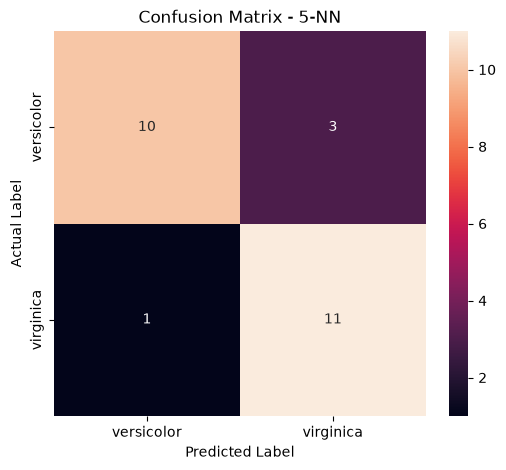

In [15]:
# Calculate the confusion matrix for 5-NN
cm = confusion_matrix(y_valid, y_pred_5)

print(cm)
# Display the confusion matrix as a heatmap
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["versicolor", "virginica"],
    yticklabels=["versicolor", "virginica"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - 5-NN")

plt.show()


### Evaluation Metrics

**Accuracy**

Accuracy measures the proportion of all predictions that were correct.

Accuracy = correct predictions / total predictions

**Precision**

Precision measures how many samples predicted as the positive class
were actually positive.

Precision = TP / (TP + FP)

In this assignment, virginica is the positive class.

**Recall**

Recall measures how many of the actual positive samples were correctly
identified.

Recall = TP / (TP + FN)

**F1 Score**

F1 score combines precision and recall into one measure. It is the
harmonic mean of precision and recall.

F1 = 2 × (Precision × Recall) / (Precision + Recall)

The confusion matrix shows the numbers of correct and incorrect
predictions for each class.

In [16]:
#PROBLEM 7
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches


def decision_region(
    X,
    y,
    model,
    step=0.01,
    title="Decision Region",
    xlabel="xlabel",
    ylabel="ylabel",
    target_names=None,
):
    """
    Draw the decision region of a trained binary classifier
    using two-dimensional features.
    """

    if target_names is None:
        target_names = ["versicolor", "virginica"]

    scatter_color = ["red", "blue"]
    contourf_color = ["pink", "skyblue"]
    n_class = 2

    # Create a grid covering the feature space
    mesh_f0, mesh_f1 = np.meshgrid(
        np.arange(
            np.min(X[:, 0]) - 0.5,
            np.max(X[:, 0]) + 0.5,
            step
        ),
        np.arange(
            np.min(X[:, 1]) - 0.5,
            np.max(X[:, 1]) + 0.5,
            step
        ),
    )

    # Convert the grid into pairs of feature values
    mesh = np.c_[
        np.ravel(mesh_f0),
        np.ravel(mesh_f1)
    ]

    # Predict the class for every point in the grid
    y_pred = model.predict(mesh).reshape(mesh_f0.shape)

    # Draw the decision regions
    plt.figure(figsize=(8, 6))

    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)

    plt.contourf(
        mesh_f0,
        mesh_f1,
        y_pred,
        n_class - 1,
        cmap=ListedColormap(contourf_color)
    )

    # Plot the actual samples
    for i, target in enumerate(np.unique(y)):
        plt.scatter(
            X[y == target][:, 0],
            X[y == target][:, 1],
            s=80,
            color=scatter_color[i],
            label=target_names[i]
        )

    plt.legend()
    plt.show()

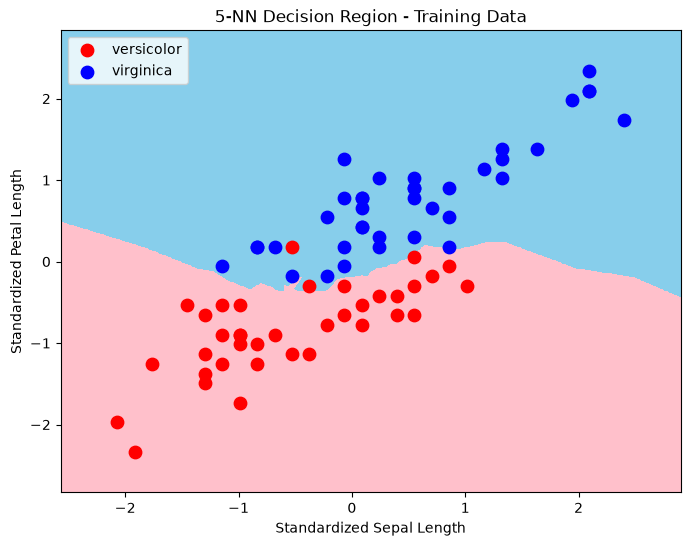

In [17]:
# Visualize the 5-NN decision region using the training data
decision_region(
    X_train_scaled,
    y_train.to_numpy(),
    knn_5,
    title="5-NN Decision Region - Training Data",
    xlabel="Standardized Sepal Length",
    ylabel="Standardized Petal Length",
    target_names=["versicolor", "virginica"]
)

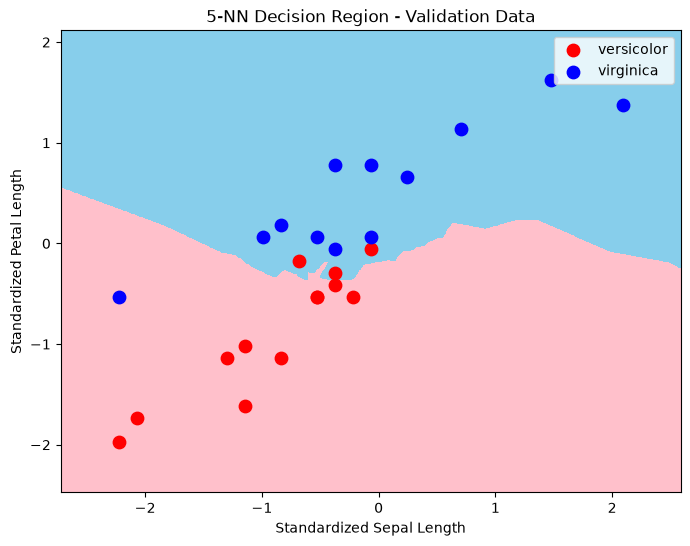

In [18]:
# Visualize the 5-NN decision region using validation data
decision_region(
    X_valid_scaled,
    y_valid.to_numpy(),
    knn_5,
    title="5-NN Decision Region - Validation Data",
    xlabel="Standardized Sepal Length",
    ylabel="Standardized Petal Length",
    target_names=["versicolor", "virginica"]
)

In [19]:
#PROBLEM 8
# Create all five classification models

models = {
    "KNN": KNeighborsClassifier(),
    
    "Logistic Regression": LogisticRegression(
        random_state=42
    ),
    
    "SVM": SVC(),
    
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    
    "Random Forest": RandomForestClassifier(
        random_state=42
    )
}

In [20]:
# Store the evaluation results
results = []

# Train and evaluate every model
for name, model in models.items():
    
    # Train the model
    model.fit(X_train_scaled, y_train)
    
    # Make predictions on validation data
    y_pred = model.predict(X_valid_scaled)
    
    # Calculate metrics
    accuracy = accuracy_score(y_valid, y_pred)
    precision = precision_score(
        y_valid,
        y_pred,
        pos_label=2
    )
    recall = recall_score(
        y_valid,
        y_pred,
        pos_label=2
    )
    f1 = f1_score(
        y_valid,
        y_pred,
        pos_label=2
    )
    
    # Save the results
    results.append({
        "Method": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

# Convert the results into a DataFrame
results_df = pd.DataFrame(results)

# Display the comparison table
results_df

,Method,Accuracy,Precision,Recall,F1 Score
0,KNN,0.84,0.785714,0.916667,0.846154
1,Logistic Regression,0.92,0.916667,0.916667,0.916667
2,SVM,0.88,0.846154,0.916667,0.880000
3,Decision Tree,0.84,0.833333,0.833333,0.833333
4,Random Forest,0.88,0.846154,0.916667,0.880000


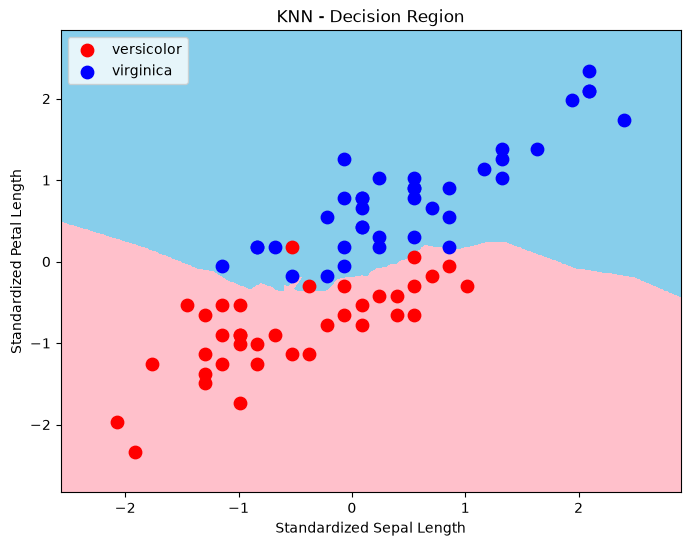

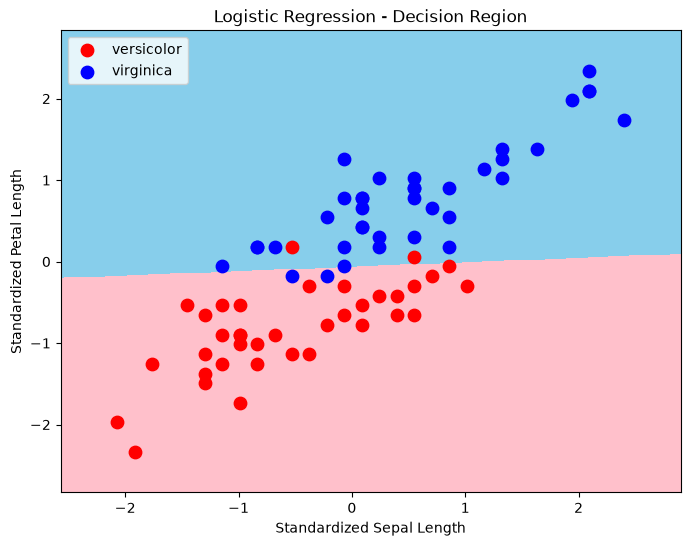

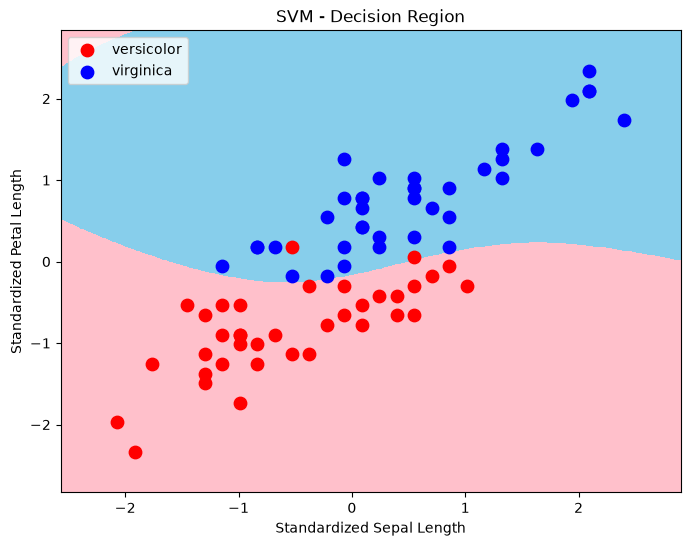

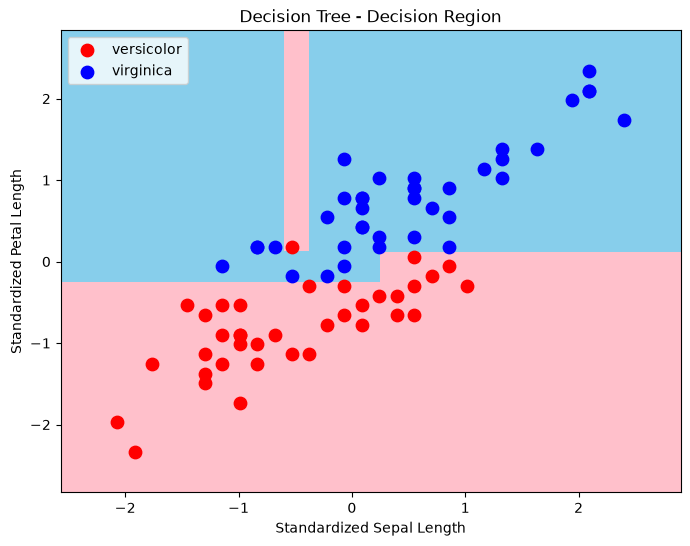

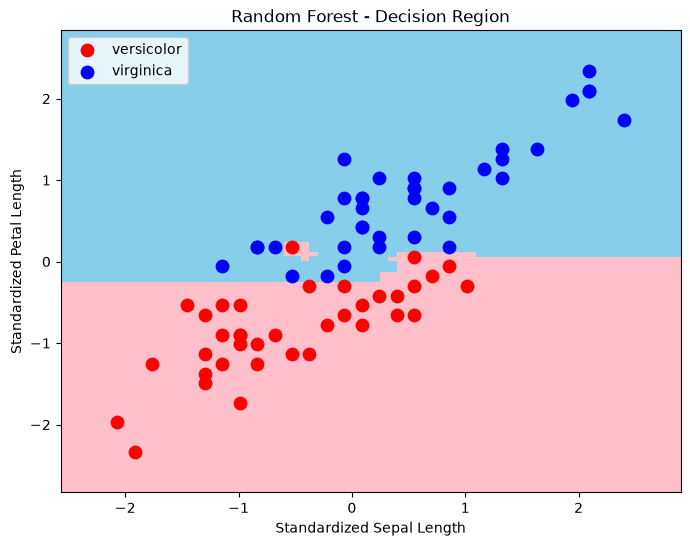

In [21]:
# Visualize the decision region of every model
for name, model in models.items():
    
    decision_region(
        X_train_scaled,
        y_train.to_numpy(),
        model,
        title=f"{name} - Decision Region",
        xlabel="Standardized Sepal Length",
        ylabel="Standardized Petal Length",
        target_names=["versicolor", "virginica"]
    )

### Comparison of Classification Methods

The five classification methods were trained using the same training
and validation datasets.

The evaluation results were compared using accuracy, precision, recall,
and F1 score.

The decision-region plots also show that the models create different
classification boundaries.

KNN creates decision regions based on nearby samples. Logistic regression
produces a relatively simple boundary, while SVM can create a different
separation boundary. Decision trees produce more segmented regions, and
random forests combine multiple decision trees.

The metric values show that the performance of the methods is not
necessarily identical, even though they were trained using the same data.

In [22]:
#PROBLEM 9
# Create the same five models for the unstandardized data

models_unscaled = {
    "KNN": KNeighborsClassifier(),
    
    "Logistic Regression": LogisticRegression(
        random_state=42
    ),
    
    "SVM": SVC(),
    
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    
    "Random Forest": RandomForestClassifier(
        random_state=42
    )
}

In [23]:
# Store results without standardization
results_unscaled = []

# Train and evaluate each model using the original features
for name, model in models_unscaled.items():
    
    # Train using unstandardized training data
    model.fit(X_train, y_train)
    
    # Predict unstandardized validation data
    y_pred = model.predict(X_valid)
    
    # Calculate metrics
    accuracy = accuracy_score(y_valid, y_pred)
    precision = precision_score(
        y_valid,
        y_pred,
        pos_label=2
    )
    recall = recall_score(
        y_valid,
        y_pred,
        pos_label=2
    )
    f1 = f1_score(
        y_valid,
        y_pred,
        pos_label=2
    )
    
    results_unscaled.append({
        "Method": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

# Convert results to a DataFrame
results_unscaled_df = pd.DataFrame(results_unscaled)

results_unscaled_df

,Method,Accuracy,Precision,Recall,F1 Score
0,KNN,0.84,0.785714,0.916667,0.846154
1,Logistic Regression,0.96,1.000000,0.916667,0.956522
2,SVM,0.88,0.846154,0.916667,0.880000
3,Decision Tree,0.84,0.833333,0.833333,0.833333
4,Random Forest,0.88,0.846154,0.916667,0.880000


In [24]:
# Add a column showing that these results are standardized
results_df["Preprocessing"] = "Standardized"

# Add a column showing that these results are not standardized
results_unscaled_df["Preprocessing"] = "Not standardized"

# Combine both result tables
comparison_df = pd.concat(
    [results_df, results_unscaled_df],
    ignore_index=True
)

# Display the comparison
comparison_df

,Method,Accuracy,Precision,Recall,F1 Score,Preprocessing
0,KNN,0.84,0.785714,0.916667,0.846154,Standardized
1,Logistic Regression,0.92,0.916667,0.916667,0.916667,Standardized
2,SVM,0.88,0.846154,0.916667,0.880000,Standardized
3,Decision Tree,0.84,0.833333,0.833333,0.833333,Standardized
4,Random Forest,0.88,0.846154,0.916667,0.880000,Standardized
5,KNN,0.84,0.785714,0.916667,0.846154,Not standardized
6,Logistic Regression,0.96,1.000000,0.916667,0.956522,Not standardized
7,SVM,0.88,0.846154,0.916667,0.880000,Not standardized
8,Decision Tree,0.84,0.833333,0.833333,0.833333,Not standardized
9,Random Forest,0.88,0.846154,0.916667,0.880000,Not standardized


### Standardization Comparison

Standardization transforms each feature so that it has approximately a
mean of 0 and a standard deviation of 1.

In this assignment, the scaler was fitted only on the training data and
then applied to both the training and validation data.

The results with and without standardization were compared using accuracy,
precision, recall, and F1 score.

Standardization can be particularly important for algorithms that depend
on distances or feature scales, such as KNN. It can also affect methods
such as logistic regression and SVM.

Tree-based methods such as decision trees and random forests generally do
not depend on feature scaling in the same way because their decisions are
based on feature thresholds.

The actual metric differences can be observed in the comparison table.

In [25]:
#PROBLEM 10
# Use all four Iris features
X_multi = iris_df[
    [
        "sepal_length",
        "sepal_width",
        "petal_length",
        "petal_width"
    ]
]

# Use all three target classes
y_multi = iris_df["target"]

# Split into training and validation data
X_multi_train, X_multi_valid, y_multi_train, y_multi_valid = train_test_split(
    X_multi,
    y_multi,
    test_size=0.25,
    random_state=42,
    stratify=y_multi
)

print("Training data:", X_multi_train.shape)
print("Validation data:", X_multi_valid.shape)

Training data: (112, 4)
Validation data: (38, 4)


In [26]:
# Create a new scaler for the multiclass experiment
multi_scaler = StandardScaler()

# Fit only on multiclass training data
multi_scaler.fit(X_multi_train)

# Standardize training features
X_multi_train_scaled = multi_scaler.transform(X_multi_train)

# Standardize validation features
X_multi_valid_scaled = multi_scaler.transform(X_multi_valid)

In [27]:
# Create the five models for multiclass classification

multi_models = {
    "KNN": KNeighborsClassifier(),
    
    "Logistic Regression": LogisticRegression(
        random_state=42
    ),
    
    "SVM": SVC(),
    
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    
    "Random Forest": RandomForestClassifier(
        random_state=42
    )
}

In [28]:
# Store multiclass results
multi_results = []

for name, model in multi_models.items():
    
    # Train the model
    model.fit(X_multi_train_scaled, y_multi_train)
    
    # Predict validation data
    y_pred = model.predict(X_multi_valid_scaled)
    
    # Accuracy
    accuracy = accuracy_score(
        y_multi_valid,
        y_pred
    )
    
    # Macro metrics
    precision_macro = precision_score(
        y_multi_valid,
        y_pred,
        average="macro"
    )
    
    recall_macro = recall_score(
        y_multi_valid,
        y_pred,
        average="macro"
    )
    
    f1_macro = f1_score(
        y_multi_valid,
        y_pred,
        average="macro"
    )
    
    # Micro metrics
    precision_micro = precision_score(
        y_multi_valid,
        y_pred,
        average="micro"
    )
    
    recall_micro = recall_score(
        y_multi_valid,
        y_pred,
        average="micro"
    )
    
    f1_micro = f1_score(
        y_multi_valid,
        y_pred,
        average="micro"
    )
    
    # Save results
    multi_results.append({
        "Method": name,
        "Accuracy": accuracy,
        "Precision Macro": precision_macro,
        "Recall Macro": recall_macro,
        "F1 Macro": f1_macro,
        "Precision Micro": precision_micro,
        "Recall Micro": recall_micro,
        "F1 Micro": f1_micro
    })

# Convert to DataFrame
multi_results_df = pd.DataFrame(multi_results)

multi_results_df

,Method,Accuracy,Precision Macro,Recall Macro,F1 Macro,Precision Micro,Recall Micro,F1 Micro
0,KNN,0.921053,0.937500,0.923077,0.922039,0.921053,0.921053,0.921053
1,Logistic Regression,0.921053,0.924603,0.923077,0.922963,0.921053,0.921053,0.921053
2,SVM,0.947368,0.948718,0.948718,0.948718,0.947368,0.947368,0.947368
3,Decision Tree,0.894737,0.903030,0.897436,0.896825,0.894737,0.894737,0.894737
4,Random Forest,0.921053,0.924603,0.923077,0.922963,0.921053,0.921053,0.921053


### Macro vs Micro Averaging

**Macro averaging** calculates the metric independently for each class
and then takes the average. Each class therefore has equal importance,
regardless of how many samples it contains.

**Micro averaging** combines the contributions from all classes before
calculating the metric. Therefore, each individual prediction contributes
equally to the final value.

For single-label multiclass classification, when all classes are included,
micro-averaged precision, recall, and F1 are equal to accuracy.

This happens because every sample receives exactly one predicted class
and exactly one true class. Therefore, the total number of true positive
predictions across all classes is the number of correct predictions.

As a result:

micro precision = micro recall = micro F1 = accuracy

In [29]:
# Display validation accuracy for every multiclass model
multi_results_df[
    ["Method", "Accuracy"]
]

# Find the model with the highest validation accuracy
best_model_row = multi_results_df.loc[
    multi_results_df["Accuracy"].idxmax()
]

print("Highest validation accuracy:")
print(best_model_row)

Highest validation accuracy:
Method                  SVM
Accuracy           0.947368
Precision Macro    0.948718
Recall Macro       0.948718
F1 Macro           0.948718
Precision Micro    0.947368
Recall Micro       0.947368
F1 Micro           0.947368
Name: 2, dtype: object


In [30]:
def multiclass_decision_region(
    X,
    y,
    model,
    feature_indices=(0, 2),
    step=0.02,
    title="Multiclass Decision Region",
    xlabel="Feature 1",
    ylabel="Feature 2",
):
    """
    Visualize a multiclass model using two selected features.

    The remaining features are fixed at their training-data mean values.
    """

    # Select the two features for visualization
    X_plot = X[:, list(feature_indices)]

    # Create a mesh covering the selected two features
    x_min = X_plot[:, 0].min() - 0.5
    x_max = X_plot[:, 0].max() + 0.5

    y_min = X_plot[:, 1].min() - 0.5
    y_max = X_plot[:, 1].max() + 0.5

    mesh_x, mesh_y = np.meshgrid(
        np.arange(x_min, x_max, step),
        np.arange(y_min, y_max, step)
    )

    # Create a matrix for model prediction
    mesh = np.zeros(
        (mesh_x.size, X.shape[1])
    )

    # Use mean values for the features not shown
    mesh[:] = np.mean(X, axis=0)

    # Replace the two selected features with mesh values
    mesh[:, feature_indices[0]] = mesh_x.ravel()
    mesh[:, feature_indices[1]] = mesh_y.ravel()

    # Predict each point in the mesh
    predictions = model.predict(mesh)

    predictions = predictions.reshape(mesh_x.shape)

    # Draw decision regions
    plt.figure(figsize=(9, 7))

    plt.contourf(
        mesh_x,
        mesh_y,
        predictions,
        alpha=0.3
    )

    # Plot actual samples
    scatter = plt.scatter(
        X_plot[:, 0],
        X_plot[:, 1],
        c=y,
        edgecolor="black",
        s=70
    )

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)

    # Create legend
    plt.legend(
        handles=scatter.legend_elements()[0],
        labels=["setosa", "versicolor", "virginica"],
        title="Species"
    )

    plt.show()

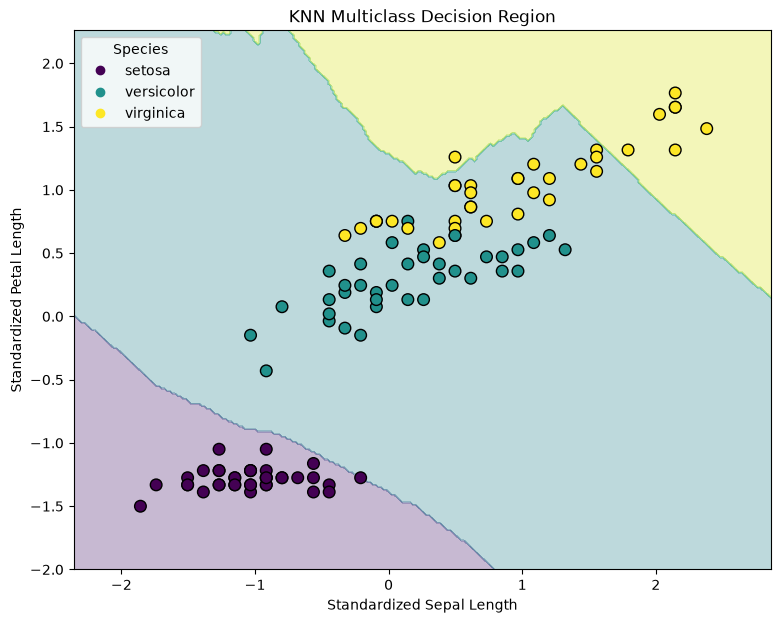

In [31]:
# Visualize one of the multiclass models
# using sepal length and petal length

multiclass_model = multi_models["KNN"]

multiclass_decision_region(
    X_multi_train_scaled,
    y_multi_train.to_numpy(),
    multiclass_model,
    feature_indices=(0, 2),
    title="KNN Multiclass Decision Region",
    xlabel="Standardized Sepal Length",
    ylabel="Standardized Petal Length"
)

# Conclusion

In this assignment, I practiced the basic workflow of a supervised
classification problem using the Iris dataset and scikit-learn.

First, I selected versicolor and virginica and used sepal length and
petal length as features. I analyzed the data using scatter plots,
boxplots, and violin plots.

I then divided the data into training and validation sets using a 75:25
ratio. Standardization was performed by fitting the StandardScaler only
on the training data and applying the learned transformation to both
training and validation data.

Next, I trained a K-nearest neighbors classifier using different numbers
of neighbors and evaluated the predictions using accuracy, precision,
recall, F1 score, and a confusion matrix.

I then compared five classification methods:

- K-nearest neighbors
- Logistic regression
- SVM
- Decision tree
- Random forest

The methods produced different evaluation results and different decision
regions.

I also compared classification with and without standardization.
Standardization is especially relevant to methods that are affected by
the scale of the features, while tree-based methods generally do not
depend on feature scaling in the same way.

Finally, I performed multiclass classification using all three Iris
species. For multiclass evaluation, I used macro and micro averaging.
Macro averaging gives equal importance to each class, while micro
averaging combines the predictions across all classes.

The experiments demonstrate the basic workflow of a classification
problem: data preparation, preprocessing, training, prediction,
evaluation, visualization, and comparison of different machine learning
methods.